# Sup. Fig. X: number of control gene sets, runtime and stability of z and q-values

Why `em.tl.score` uses 100 control sets by default and 1000 with `compute_q_vals=True`, for 10, 20, 50, 100, 500 and 1000
control sets. a: runtime on three cases (one unsigned signature on Visium; a signed signature, whose weights are refitted
for every control set; Visium HD). b-e: stability across 10 runs (`random_state` 0-9, i.e. different draws of the control
sets) on mouse brain Visium, top-10 signatures of the pyramidal layer and the striatum: agreement of z and of the q-values
between runs, agreement of the calls (q < 0.05) between runs, and spots called. The smallest attainable empirical p is
1 / (n + 1), so q-values need many more control sets than z does. Source data are saved as CSV next to each figure.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import anndata as ad
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import pickle
import time

from itertools import combinations
from scipy.stats import spearmanr

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
from helpers import set_box_ratio

In [6]:
colours = {"compute_q_vals=False": "#2f0bdf", "compute_q_vals=True": "#a393f8"}
mode_labels = {"compute_q_vals=False": "No q values", "compute_q_vals=True": "q values"}
null_colour = "#2f0bdf"
n_grid = [10, 20, 50, 100, 500, 1000]
n_runs = 10
n_runs_runtime = 3

In [7]:
# 1. Load data and signatures
# mouse brain Visium
adata = sc.read_h5ad(processed_data + "visium_brain_adata.h5ad")

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

signatures_dict = {
    cell_type_1: signature_dict_pyramidal[f"{cell_type_1}_top10"],
    cell_type_2: signature_dict_striatum[f"{cell_type_2}_top10"],
}

# breast cancer Visium (two slides) and the signed HRD signature (09_01 cell 8)
breast = sc.read_h5ad(processed_data + "adata_slides_0_3.h5ad")
sc.pp.normalize_total(breast, target_sum=1e4)
sc.pp.log1p(breast)
breast.obs["batch"] = breast.obs["batch"].astype(str)
hrd = pd.read_csv(project_dir + "signature_all_phenotypes.csv", index_col=0)["HRD"].dropna()
hrd = hrd[hrd.index.isin(breast.var_names)]
hrd_up, hrd_down = hrd[hrd > 0].index.tolist(), hrd[hrd < 0].index.tolist()

# Visium HD (02 cell 29; 16-um bins, log-normalised) and the top-20 pyramidal signature (02 cell 9)
visiumhd = sc.read_h5ad(processed_data + "visiumhd_pyramidal_layer_scores.h5ad")

In [8]:
# 2. Sup. Fig. Xa: runtime per signature, with and without q-values (expression, slide and coordinates only)
runtime_tasks = {
    f"Mouse brain Visium\n10 genes ({adata.n_obs:,} spots)": (adata, signatures_dict[cell_type_1], {}),
    f"Breast cancer Visium, signed HRD\n{len(hrd_up)} up + {len(hrd_down)} down genes ({breast.n_obs:,} spots)": (
        breast, {"up": hrd_up, "down": hrd_down}, {"batch_key": "batch"}),
    f"Visium HD\n20 genes ({visiumhd.n_obs:,} bins)": (
        visiumhd, signature_dict_pyramidal[f"{cell_type_1}_top20"], {"n_neighbors": 50}),
}
runtime_rows = []
for task, (data, genes, kwargs) in runtime_tasks.items():
    obs = data.obs[["batch"]].copy() if "batch_key" in kwargs else pd.DataFrame(index=data.obs_names)
    light = ad.AnnData(X=data.X, obs=obs, var=pd.DataFrame(index=data.var_names))
    light.obsm["spatial"] = np.asarray(data.obsm["spatial"])
    em.tl.score(light, gene_set={"sig": genes}, n_control_sets=10, **kwargs)  # one-off start-up costs
    for n in n_grid:
        for run in range(n_runs_runtime):
            for compute_q in (False, True):
                t0 = time.perf_counter()
                em.tl.score(light, gene_set={"sig": genes}, n_control_sets=n, compute_q_vals=compute_q,
                            random_state=run, **kwargs)
                runtime_rows.append({"dataset": task.replace("\n", ", "), "n control sets": n, "run": run,
                                     "setting": f"compute_q_vals={compute_q}", "seconds": time.perf_counter() - t0})
runtime = pd.DataFrame(runtime_rows)
runtime_summary = (
    runtime.groupby(["dataset", "setting", "n control sets"], sort=False)["seconds"]
    .agg(mean="mean", sd="std", n_values="count").reset_index()
)
print(runtime_summary.pivot_table(index=["dataset", "n control sets"], columns="setting", values="mean", sort=False)
      .round(2).to_string())

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring sig: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring sig: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 30.38it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring sig: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring sig: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 30.23it/s]

... (398 outputs left out)

Scoring sig: 13/20 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring sig: 13/20 genes found: 100%|██████████| 1/1 [00:00<00:00,  6.56it/s]

Scoring sig: 13/20 genes found: 100%|██████████| 1/1 [00:00<00:00,  6.50it/s]

setting                                                                                compute_q_vals=False  compute_q_vals=True
dataset                                                                n control sets                                           
Mouse brain Visium, 10 genes (2,688 spots)                             10                              1.14                 1.16
                                                                       20                              1.16                 1.19
                                                                       50                              1.15                 1.16
                                                                       100                             1.18                 1.18
                                                                       500                             1.22                 1.22
                                                                       1000                      

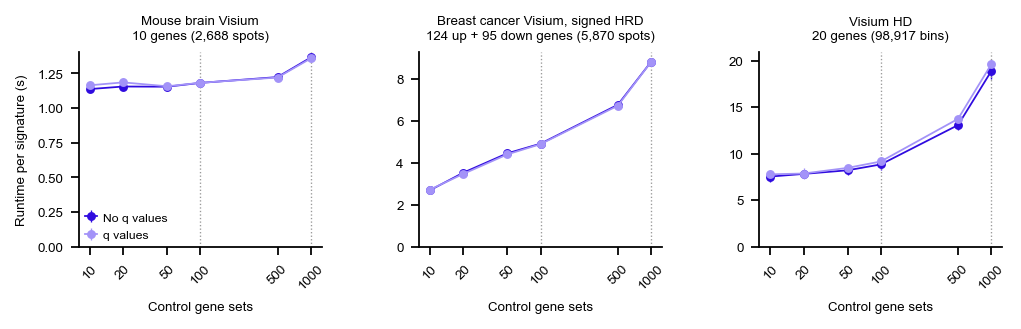

In [9]:
# Extended Data Fig. 5e: one panel per case; dotted lines: the defaults, 100 (compute_q_vals=False) and 1000 (compute_q_vals=True)
fig, axes = plt.subplots(1, len(runtime_tasks), figsize=(7.4, 2.3), gridspec_kw={"wspace": 0.4})
for ax, task in zip(axes, runtime_tasks):
    for setting, colour in colours.items():
        d = runtime_summary[(runtime_summary.dataset == task.replace("\n", ", ")) & (runtime_summary.setting == setting)]
        ax.errorbar(d["n control sets"], d["mean"], yerr=d["sd"], fmt="o-", color=colour, ms=3, lw=0.8, elinewidth=0.6,
                    capsize=0, label=mode_labels[setting])
    for n in (100, 1000):
        ax.axvline(n, ls=":", c="0.6", lw=0.6)
    ax.set_xscale("log")
    ax.set_xticks(n_grid)
    ax.set_xticklabels(n_grid, rotation=45)
    ax.minorticks_off()
    ax.set_ylim(bottom=0)
    ax.set_xlabel("Control gene sets")
    ax.set_title(task, fontsize=6)
    ax.set_box_aspect(1)
    sns.despine(ax=ax)
axes[0].set_ylabel("Runtime per signature (s)")
axes[0].legend(frameon=False, loc="lower left", fontsize=5.5)
set_box_ratio(fig)
plt.savefig(figure_dir + "ExtendedDataFig5e_runtime_control_sets.pdf", bbox_inches="tight")
plt.show()
runtime_summary.to_csv(source_dir + "ExtendedDataFig5e_runtime_control_sets.csv", index=False)

In [10]:
# 3. Sup. Fig. Xb-e: every signature with every number of control sets, 10 runs each (mouse brain Visium)
light = ad.AnnData(X=adata.X, obs=pd.DataFrame(index=adata.obs_names), var=pd.DataFrame(index=adata.var_names))
light.obsm["spatial"] = np.asarray(adata.obsm["spatial"])

z_runs, q_runs = {}, {}
for n in n_grid:
    for run in range(n_runs):
        for ct, genes in signatures_dict.items():
            em.tl.score(light, gene_set=genes, score_key=ct, n_control_sets=n, compute_q_vals=True, random_state=run)
            z_runs[(ct, n, run)] = light.obs[f"{ct}_score"].values.copy()
            q_runs[(ct, n, run)] = light.obs[f"{ct}_q"].values.copy()

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 30.50it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 30.24it/s]

... (350 outputs left out)

Scoring Pyramidal_layer: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 29.99it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 29.70it/s]

In [11]:
# 4. Agreement between runs (all pairs of runs) and spots called per run
pair_rows, call_rows = [], []
for ct in signatures_dict:
    for n in n_grid:
        called = [q_runs[(ct, n, run)] < 0.05 for run in range(n_runs)]
        for a, b in combinations(range(n_runs), 2):
            union = (called[a] | called[b]).sum()
            pair_rows.append({
                "signature": ct, "n control sets": n,
                "Spearman z": spearmanr(z_runs[(ct, n, a)], z_runs[(ct, n, b)])[0],
                "Spearman q": spearmanr(q_runs[(ct, n, a)], q_runs[(ct, n, b)])[0],
                "Jaccard q < 0.05": (called[a] & called[b]).sum() / union if union else np.nan,
            })
        for run in range(n_runs):
            call_rows.append({"signature": ct, "n control sets": n, "% spots q < 0.05": 100 * called[run].mean()})

agreement = pd.DataFrame(pair_rows).melt(id_vars=["signature", "n control sets"], var_name="metric", value_name="value")
calls = pd.DataFrame(call_rows).melt(id_vars=["signature", "n control sets"], var_name="metric", value_name="value")
stability = (
    pd.concat([agreement, calls])
    .groupby(["signature", "metric", "n control sets"], sort=False)["value"]
    .agg(mean="mean", sd="std", n_values="count")
    .reset_index()
)
stability["smallest attainable p"] = 1 / (stability["n control sets"] + 1)

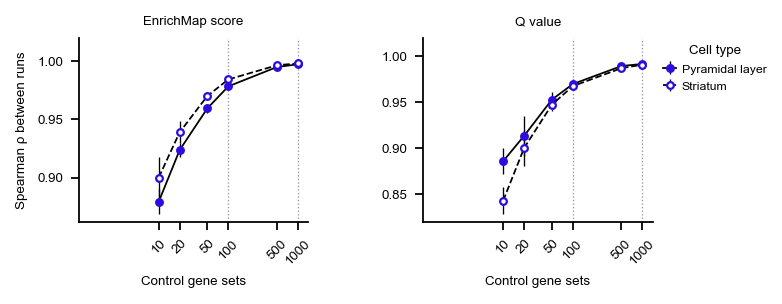

In [12]:
# Extended Data Fig. 5f: agreement of z and of the q-values between runs (points: mean, whiskers: SD over the pairs of
# runs; filled: pyramidal layer, open: striatum; dotted lines: the defaults)
panels = [("Spearman z", "EnrichMap score"), ("Spearman q", "Q value")]
fig, axes = plt.subplots(1, 2, figsize=(4.6, 2.2), sharex=True, gridspec_kw={"wspace": 0.5})
for ax, (metric, title) in zip(axes, panels):
    for ct, is_open in zip(signatures_dict, (False, True)):
        d = stability[(stability.signature == ct) & (stability.metric == metric)]
        ax.errorbar(d["n control sets"], d["mean"], yerr=d["sd"], fmt="o--" if is_open else "o-", color="k", ms=3, lw=0.8,
                    mfc="white" if is_open else null_colour, mec=null_colour, elinewidth=0.6, capsize=0,
                    label=ct.replace("_", " "))
    for n in (100, 1000):
        ax.axvline(n, ls=":", c="0.6", lw=0.6)
    ax.set_xscale("log")
    ax.set_xticks(n_grid)
    ax.set_xticklabels(n_grid, rotation=45)
    ax.minorticks_off()
    ax.set_ylim(None, 1.02)
    ax.set_xlabel("Control gene sets")
    ax.set_title(title)
    sns.despine(ax=ax)
axes[0].set_ylabel("Spearman ρ between runs")
axes[1].legend(frameon=False, fontsize=5.5, title="Cell type", title_fontsize=6, loc="upper left", bbox_to_anchor=(1.02, 1.0))
set_box_ratio(fig)
plt.savefig(figure_dir + "ExtendedDataFig5f_stability_control_sets.pdf", bbox_inches="tight")
plt.show()
stability[stability.metric.isin([m for m, _ in panels])].to_csv(source_dir + "ExtendedDataFig5f_stability_control_sets.csv", index=False)